# Regression Track — Notebook 05
# 7. Feature Engineering

**Input:** `artifacts/reg_04_cleaned.joblib`
**Output:** `artifacts/reg_05_features.joblib`

---

### Purpose

The EDA in Notebook 03 found strong structure that the raw columns cannot
express. This notebook converts those findings into features.

**The rule we hold ourselves to:** every engineered feature must be traceable
to a specific observation from the EDA. We are not adding features because
they are conventional; each one is a response to something we measured.

### Is feature engineering a leakage risk?

This is worth addressing head-on, because it is a common viva question.
Engineering features *before* the train/test split is safe **only if each new
value is computed from that row alone**. Every transformation below is
row-wise: `Month` comes from that row's own date; `sin_hour` comes from that
row's own hour. No global statistic (no mean, no median, no target average) is
used, so no information crosses from test rows into training rows.

By contrast, a feature such as "average demand for this hour" **would** leak,
because the average would be computed over rows that end up in the test set.
We deliberately avoid all such target-derived features. Anything that requires
fitting — scaling, encoding, imputation — is deferred to the pipeline in
Notebook 06, where it is fitted on training data only.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    load_artifact,
    save_artifact,
    save_figure,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

df = load_artifact("reg_04_cleaned")
TARGET = "Rented Bike Count"

print(f"\nIncoming shape: {df.shape}")
print(f"Incoming columns: {list(df.columns)}")

[loaded] artifacts/reg_04_cleaned.joblib

Incoming shape: (8465, 13)
Incoming columns: ['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday']


---
## 7.1 Calendar features from `Date`

**Motivation (EDA §5.F.2, §5.F.3).** `Date` is currently a text string, which
is useless to every algorithm in the project. But it encodes month, day of
week and weekend status — and the EDA showed that weekday and weekend hours
have genuinely different demand *shapes*, not just different levels.

In [2]:
date_parsed = pd.to_datetime(df["Date"], format="%d/%m/%Y")

df["Year"] = date_parsed.dt.year
df["Month"] = date_parsed.dt.month
df["Day"] = date_parsed.dt.day
df["DayOfWeek"] = date_parsed.dt.dayofweek          # Monday = 0 … Sunday = 6
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)  # 1 = Saturday or Sunday

section("CALENDAR FEATURES CREATED")
print(df[["Date", "Year", "Month", "Day", "DayOfWeek", "IsWeekend"]].head(3).to_string(index=False))
print()
print(f"Year values present : {sorted(df['Year'].unique().tolist())}")
print(f"Weekend rows        : {int(df['IsWeekend'].sum()):,} "
      f"({100 * df['IsWeekend'].mean():.1f}%)")

CALENDAR FEATURES CREATED
      Date  Year  Month  Day  DayOfWeek  IsWeekend
01/12/2017  2017     12    1          4          0
01/12/2017  2017     12    1          4          0
01/12/2017  2017     12    1          4          0

Year values present : [2017, 2018]
Weekend rows        : 2,441 (28.8%)


| Feature | How it is created | Why it may help |
|---|---|---|
| `Year` | `Date.dt.year` | Only two values (2017, 2018) and they split the calendar, so it mostly duplicates `Month`. Kept for completeness but expected to be near-useless — a prediction we check against feature importance in Notebook 09. |
| `Month` | `Date.dt.month` | EDA §5.F.2 showed a strong annual cycle. Gives finer resolution than the four `Seasons` categories. |
| `Day` | `Date.dt.day` | Day-of-month has no theoretical reason to matter. Included as a **deliberate control**: if it ranks high in feature importance, that is a warning sign of overfitting. |
| `DayOfWeek` | `Date.dt.dayofweek` | EDA §5.F.3 showed the weekday/weekend profiles differ. |
| `IsWeekend` | `DayOfWeek >= 5` | Gives linear models direct access to the weekday/weekend split, which they cannot otherwise extract from the ordinal `DayOfWeek` (Saturday = 5 is not "5 units more weekend" than Monday). |

---
## 7.2 Cyclical encoding of `Hour`

**Motivation (EDA §5.F.1).** `Hour` is the strongest structural driver in the
dataset — an 11× swing from trough to peak. But as a plain integer it carries
a false message: it tells the model that hour 23 and hour 0 are 23 units
apart, when in reality they are adjacent and both quiet.

The standard fix is to map the hour onto a circle:

$$\text{sin\_hour} = \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right),
\qquad
\text{cos\_hour} = \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$$

Two components are needed, not one: sine alone would give 06:00 and 18:00 the
same value. Together the pair identifies every hour uniquely while keeping
23:00 and 00:00 close together in feature space.

In [3]:
df["sin_hour"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["cos_hour"] = np.cos(2 * np.pi * df["Hour"] / 24)

# The same idea applied to the annual cycle: December and January are adjacent.
df["sin_month"] = np.sin(2 * np.pi * df["Month"] / 12)
df["cos_month"] = np.cos(2 * np.pi * df["Month"] / 12)

section("CYCLICAL ENCODING — DISTANCE BETWEEN 23:00 AND 00:00")
raw_gap = abs(23 - 0)
cyc_gap = np.hypot(
    np.sin(2 * np.pi * 23 / 24) - np.sin(0),
    np.cos(2 * np.pi * 23 / 24) - np.cos(0),
)
mid_gap = abs(12 - 0)
print(f"Raw 'Hour' distance,    23:00 to 00:00 : {raw_gap:.3f}")
print(f"Raw 'Hour' distance,    12:00 to 00:00 : {mid_gap:.3f}")
print(f"Cyclical distance,      23:00 to 00:00 : {cyc_gap:.3f}   <-- correctly small")
print(f"Cyclical distance,      12:00 to 00:00 : "
      f"{np.hypot(np.sin(np.pi) - 0, np.cos(np.pi) - 1):.3f}   <-- correctly large")

CYCLICAL ENCODING — DISTANCE BETWEEN 23:00 AND 00:00
Raw 'Hour' distance,    23:00 to 00:00 : 23.000
Raw 'Hour' distance,    12:00 to 00:00 : 12.000
Cyclical distance,      23:00 to 00:00 : 0.261   <-- correctly small
Cyclical distance,      12:00 to 00:00 : 2.000   <-- correctly large


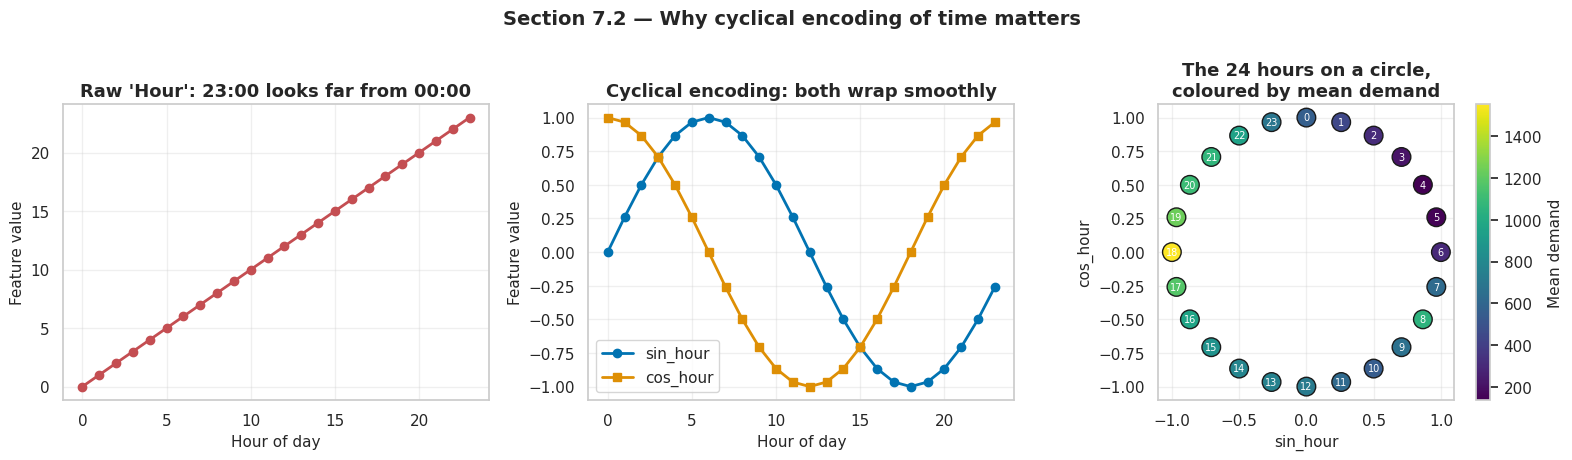

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

hours = np.arange(24)
axes[0].plot(hours, hours, marker="o", color="#C44E52", lw=2)
axes[0].set_title("Raw 'Hour': 23:00 looks far from 00:00")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Feature value")

axes[1].plot(hours, np.sin(2 * np.pi * hours / 24), marker="o", label="sin_hour", lw=2)
axes[1].plot(hours, np.cos(2 * np.pi * hours / 24), marker="s", label="cos_hour", lw=2)
axes[1].set_title("Cyclical encoding: both wrap smoothly")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Feature value")
axes[1].legend()

mean_by_hour = df.groupby("Hour", observed=True)[TARGET].mean()
sc = axes[2].scatter(np.sin(2 * np.pi * hours / 24), np.cos(2 * np.pi * hours / 24),
                     c=mean_by_hour.values, cmap="viridis", s=180, edgecolor="k", zorder=3)
for h in hours:
    axes[2].annotate(str(h), (np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)),
                     fontsize=7, ha="center", va="center", color="white", zorder=4)
axes[2].set_title("The 24 hours on a circle,\ncoloured by mean demand")
axes[2].set_xlabel("sin_hour")
axes[2].set_ylabel("cos_hour")
axes[2].set_aspect("equal")
plt.colorbar(sc, ax=axes[2], label="Mean demand")

fig.suptitle("Section 7.2 — Why cyclical encoding of time matters",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_fe_cyclical", fig)
plt.show()

**Interpretation.** In the right-hand panel the bright (high-demand) hours
form a coherent arc around the evening side of the circle, and 23 sits
directly next to 0 as it should. This is the representation that distance-based
models (KNN) and kernel models (SVR) actually need: under the raw integer
encoding, KNN would consider 23:00 the *least* similar hour to 00:00, which is
exactly backwards.

**Note:** we keep the raw `Hour` column as well. Tree-based models handle it
perfectly well — a tree can isolate hour 18 with two splits and does not care
about the wrap-around — and dropping it would remove information that trees use
efficiently. Keeping both lets each model family use whichever representation
suits it.

---
## 7.3 Rush-hour indicator

**Motivation (EDA §5.F.1, §5.F.3).** The twin peaks at 08:00 and 18:00 are
driven by commuting. We give the models a direct binary flag for those hours —
but only when it is actually a commute, i.e. on a working day.

In [5]:
MORNING_RUSH = [7, 8, 9]      # from the 08:00 peak in EDA §5.F.1
EVENING_RUSH = [17, 18, 19, 20]  # from the broader, larger 18:00 peak

is_rush_hour_clock = df["Hour"].isin(MORNING_RUSH + EVENING_RUSH)
is_working_day = (df["IsWeekend"] == 0) & (df["Holiday"] == "No Holiday")

df["RushHour"] = (is_rush_hour_clock & is_working_day).astype(int)

section("RUSH-HOUR FLAG — DOES IT SEPARATE DEMAND?")
print(f"Rush hours flagged: {int(df['RushHour'].sum()):,} "
      f"({100 * df['RushHour'].mean():.1f}% of rows)")
print()
print(df.groupby("RushHour", observed=True)[TARGET]
      .agg(Hours="count", Mean="mean", Median="median", Std="std")
      .round(1).to_string())

rush_mean = df.loc[df["RushHour"] == 1, TARGET].mean()
other_mean = df.loc[df["RushHour"] == 0, TARGET].mean()
print(f"\nRush hours average {rush_mean / other_mean:.2f}× the demand of other hours.")

RUSH-HOUR FLAG — DOES IT SEPARATE DEMAND?
Rush hours flagged: 1,666 (19.7% of rows)

          Hours    Mean  Median    Std
RushHour                              
0          6799   615.4   436.0  539.6
1          1666  1193.4  1107.0  800.2

Rush hours average 1.94× the demand of other hours.


**Why this may help.** The flag is a *conjunction* — "commuting clock time
AND a working day" — and that conjunction is something a linear model cannot
build for itself. A linear model can add an hour effect and add a weekend
effect, but it cannot express "08:00 matters a lot on Tuesday and very little
on Sunday" without an explicit interaction term. Handing it the interaction
pre-computed is the whole point.

**Caveat we should state.** The hour windows (7–9, 17–20) are chosen from the
EDA curve, so they are informed by the data. They were chosen from the
*overall* demand profile, not by testing which windows maximise test-set
accuracy — that would be a subtle form of leakage. Tree models could discover
these thresholds by themselves; the flag mainly benefits the linear family.

---
## 7.4 Weather condition flags

**Motivation (EDA §5.E).** The rainfall effect is a **step, not a slope**:
demand fell from 766 to 251 at the first drop of rain, then declined only
gradually. A linear model given `Rainfall(mm)` must represent this as one
constant slope, which fits neither the cliff nor the plateau. A binary
"is it raining" flag captures the cliff directly.

In [6]:
df["IsRaining"] = (df["Rainfall(mm)"] > 0).astype(int)
df["IsSnowing"] = (df["Snowfall (cm)"] > 0).astype(int)

# Daylight: solar radiation is exactly zero at night (EDA §5.B).
df["IsDaylight"] = (df["Solar Radiation (MJ/m2)"] > 0).astype(int)

section("WEATHER FLAGS")
for flag in ["IsRaining", "IsSnowing", "IsDaylight"]:
    grp = df.groupby(flag, observed=True)[TARGET].agg(Hours="count", Mean="mean").round(1)
    print(f"\n{flag}:")
    print(grp.to_string())

WEATHER FLAGS

IsRaining:
           Hours   Mean
IsRaining              
0           7949  765.6
1            516  167.3

IsSnowing:
           Hours   Mean
IsSnowing              
0           8022  759.2
1            443  185.1

IsDaylight:
            Hours   Mean
IsDaylight              
0            4151  504.5
1            4314  945.3


**Why these may help.** Each flag encodes a threshold that matters far more
than the continuous magnitude behind it. We keep the original continuous
columns alongside the flags, so the models can still use intensity where it
helps — the flag adds a representation, it does not replace one.

**`IsDaylight` is partly redundant** with the cyclical hour features and with
solar radiation itself. We include it because it is cheap and interpretable,
and we will look at whether the model actually uses it in Notebook 09. Being
honest about which engineered features turn out not to earn their place is
part of the analysis.

---
## 7.5 Temperature comfort band

**Motivation (EDA §5.E).** The temperature/demand curve is an **inverted U** —
demand rises with warmth up to roughly 25 °C and then flattens and declines.
A linear model with a single temperature coefficient cannot represent a
turning point at all.

In [7]:
# Bands chosen from the shape of the binned-mean curve in EDA §5.E, not by
# testing against the target.
TEMP_BINS = [-np.inf, 0, 10, 20, 30, np.inf]
TEMP_LABELS = ["Freezing", "Cold", "Mild", "Comfortable", "Hot"]

df["TempBand"] = pd.cut(df["Temperature(°C)"], bins=TEMP_BINS, labels=TEMP_LABELS)

section("DEMAND BY TEMPERATURE BAND (all hours)")
print(df.groupby("TempBand", observed=True)[TARGET]
      .agg(Hours="count", Mean="mean", Median="median")
      .round(1).to_string())

# All-hours means are diluted by night-time rows, which are cold AND quiet for
# reasons unrelated to comfort. Restricting to daytime isolates the temperature
# effect and makes the turning point much clearer.
section("DEMAND BY TEMPERATURE BAND (daytime 10:00-20:00 only)")
daytime = df[df["Hour"].between(10, 20)]
print(daytime.groupby("TempBand", observed=True)[TARGET]
      .agg(Hours="count", Mean="mean", Median="median")
      .round(1).to_string())

DEMAND BY TEMPERATURE BAND (all hours)
             Hours    Mean  Median
TempBand                          
Freezing      1454   199.5   170.0
Cold          2117   429.9   335.0
Mild          2058   841.7   792.0
Comfortable   2324  1150.4  1075.0
Hot            512  1106.4   903.0
DEMAND BY TEMPERATURE BAND (daytime 10:00-20:00 only)
             Hours    Mean  Median
TempBand                          
Freezing       510   248.2   223.0
Cold           887   488.8   405.0
Mild           883  1075.7  1015.0
Comfortable   1173  1414.6  1273.0
Hot            430  1105.7   846.0


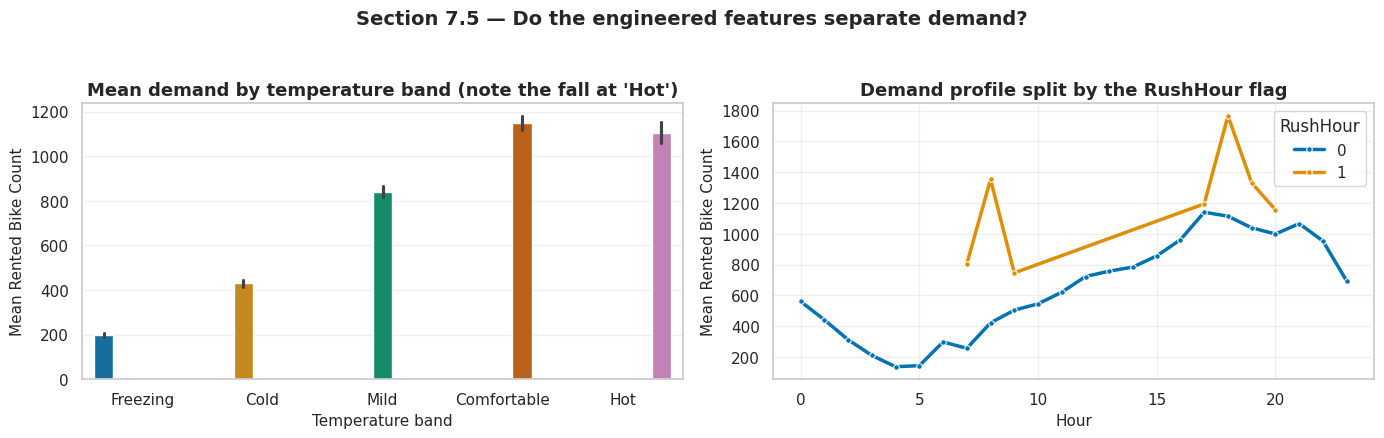

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

sns.barplot(data=df, x="TempBand", y=TARGET, hue="TempBand", legend=False,
            palette="colorblind", errorbar=("ci", 95), ax=axes[0])
axes[0].set_title("Mean demand by temperature band (note the fall at 'Hot')")
axes[0].set_ylabel("Mean Rented Bike Count")
axes[0].set_xlabel("Temperature band")

rush_profile = df.groupby(["RushHour", "Hour"], observed=True)[TARGET].mean().reset_index()
sns.lineplot(data=rush_profile, x="Hour", y=TARGET, hue="RushHour",
             palette="colorblind", lw=2.5, marker="o", markersize=4, ax=axes[1])
axes[1].set_title("Demand profile split by the RushHour flag")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Mean Rented Bike Count")
axes[1].legend(title="RushHour")

fig.suptitle("Section 7.5 — Do the engineered features separate demand?",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_fe_bands", fig)
plt.show()

**Observation.** Across all hours, mean demand climbs from `Freezing` (200) to
`Comfortable` (1,150) and then **falls** to 1,106 in the `Hot` band. The drop
is modest in the all-hours view, but restricting to daytime hours makes it
unambiguous: 1,506 bikes in the 25–30 °C range against 1,106 above 30 °C, a
fall of roughly 27%. The turning point predicted by the EDA is real.

**Interpretation.** `TempBand` gives every model — including the strictly
linear ones — a way to express "too hot is also bad". It is a coarse,
piecewise-constant approximation of the inverted U, and it is precisely the
kind of shape a single linear coefficient cannot produce.

The gap between the two tables is itself a useful lesson: the all-hours figures
**understate** the effect because cold hours and night hours overlap heavily.
Temperature and hour are entangled, which is one more reason a model that can
represent interactions should outperform an additive one.

---
## 7.6 Features considered and deliberately rejected

Documenting what we chose *not* to build is as informative as documenting what
we built.

| Candidate feature | Why rejected |
|---|---|
| Lag features (demand 1 h / 24 h ago) | Would almost certainly be the strongest predictors, but under a **random** train/test split the lagged row often lands in the other split, leaking the target. Also unavailable in the real use case, where we forecast ahead without knowing recent counts. Excluded as a leakage risk. |
| Rolling mean of past demand | Same leakage problem, worse: the window spans both splits. |
| Mean demand per hour / per season (target encoding) | Computed from the target. Fitting it before the split leaks directly; fitting it inside the pipeline is possible but adds complexity for little gain here. |
| Apparent ("feels-like") temperature | Requires a wind-chill/heat-index formula not supplied with the dataset, and temperature + humidity + wind are all already available for the model to combine. |
| Dropping `Dew point temperature` for collinearity (r = 0.91) | Tempting, but Ridge and ElasticNet are in the algorithm list precisely to handle collinearity, and trees are unaffected. Dropping it would remove a real signal to fix a problem only some models have. We keep it and interpret linear coefficients cautiously instead. |
| Interaction terms (temperature × hour, etc.) | Polynomial Regression generates these systematically in Notebook 07, and tree ensembles learn them implicitly. Hand-crafting them would duplicate that work. |

---
## 7.7 Final feature set

In [9]:
# `Date` has served its purpose — every usable piece of it is now an explicit
# column, and the raw string cannot be fed to a model.
df_model = df.drop(columns=["Date"])

engineered = ["Year", "Month", "Day", "DayOfWeek", "IsWeekend", "sin_hour", "cos_hour",
              "sin_month", "cos_month", "RushHour", "IsRaining", "IsSnowing",
              "IsDaylight", "TempBand"]

section("FEATURE SET SUMMARY")
print(f"Rows                       : {len(df_model):,}")
print(f"Total columns              : {df_model.shape[1]} (including the target)")
print(f"Original predictors kept   : {df_model.shape[1] - 1 - len(engineered)}")
print(f"Engineered predictors added: {len(engineered)}")
print()
print("All predictors:")
for i, col in enumerate([c for c in df_model.columns if c != TARGET], start=1):
    tag = "engineered" if col in engineered else "original"
    print(f"  {i:>2}. {col:<28} [{tag}]")

FEATURE SET SUMMARY
Rows                       : 8,465
Total columns              : 26 (including the target)
Original predictors kept   : 11
Engineered predictors added: 14

All predictors:
   1. Hour                         [original]
   2. Temperature(°C)              [original]
   3. Humidity(%)                  [original]
   4. Wind speed (m/s)             [original]
   5. Visibility (10m)             [original]
   6. Dew point temperature(°C)    [original]
   7. Solar Radiation (MJ/m2)      [original]
   8. Rainfall(mm)                 [original]
   9. Snowfall (cm)                [original]
  10. Seasons                      [original]
  11. Holiday                      [original]
  12. Year                         [engineered]
  13. Month                        [engineered]
  14. Day                          [engineered]
  15. DayOfWeek                    [engineered]
  16. IsWeekend                    [engineered]
  17. sin_hour                     [engineered]
  18. cos_hour 

In [10]:
section("NO MISSING VALUES INTRODUCED BY FEATURE ENGINEERING")
print(df_model.isna().sum().to_string())
print(f"\nTotal missing: {int(df_model.isna().sum().sum())}")

df_model.head()

NO MISSING VALUES INTRODUCED BY FEATURE ENGINEERING
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Year                         0
Month                        0
Day                          0
DayOfWeek                    0
IsWeekend                    0
sin_hour                     0
cos_hour                     0
sin_month                    0
cos_month                    0
RushHour                     0
IsRaining                    0
IsSnowing                    0
IsDaylight                   0
TempBand                     0

Total missing: 0


,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),...,IsWeekend,sin_hour,cos_hour,sin_month,cos_month,RushHour,IsRaining,IsSnowing,IsDaylight,TempBand
0,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,...,0,0.000000,1.000000,-2.449294e-16,1.0,0,0,0,0,Freezing
1,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,...,0,0.258819,0.965926,-2.449294e-16,1.0,0,0,0,0,Freezing
2,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,...,0,0.500000,0.866025,-2.449294e-16,1.0,0,0,0,0,Freezing
3,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,...,0,0.707107,0.707107,-2.449294e-16,1.0,0,0,0,0,Freezing
4,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,...,0,0.866025,0.500000,-2.449294e-16,1.0,0,0,0,0,Freezing


### Correlation of the engineered features with the target

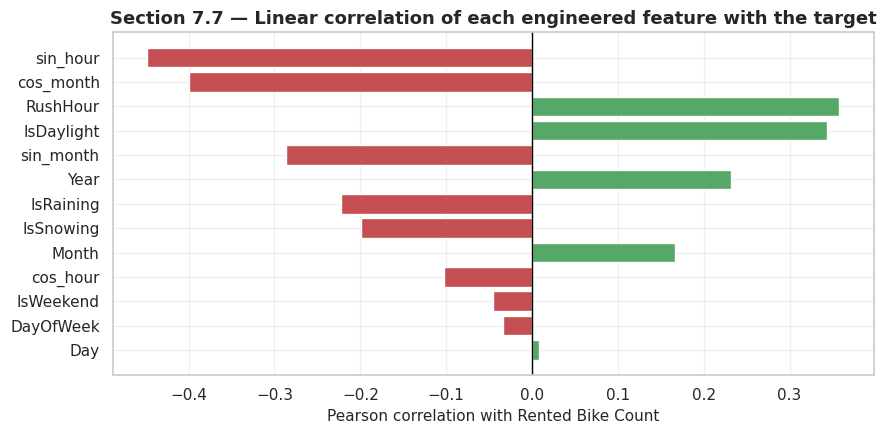

sin_hour     -0.448
cos_month    -0.400
RushHour      0.358
IsDaylight    0.343
sin_month    -0.287
Year          0.232
IsRaining    -0.223
IsSnowing    -0.199
Month         0.167
cos_hour     -0.103
IsWeekend    -0.046
DayOfWeek    -0.034
Day           0.008


In [11]:
numeric_engineered = [c for c in engineered if c != "TempBand"]
eng_corr = (
    df_model[numeric_engineered + [TARGET]].corr()[TARGET]
    .drop(TARGET).sort_values(key=abs, ascending=False).round(3)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#55A868" if v > 0 else "#C44E52" for v in eng_corr.values]
ax.barh(eng_corr.index, eng_corr.values, color=colors)
ax.axvline(0, color="black", lw=1)
ax.invert_yaxis()
ax.set_xlabel("Pearson correlation with Rented Bike Count")
ax.set_title("Section 7.7 — Linear correlation of each engineered feature with the target")
plt.tight_layout()
save_figure("reg_fe_correlation", fig)
plt.show()

print(eng_corr.to_string())

**Observation.** `sin_hour` (−0.45), `cos_month` (−0.40) and `RushHour`
(+0.36) show the strongest linear correlations among the new features.
`Day` is essentially flat at +0.008, exactly as predicted in §7.1 for a feature
with no theoretical reason to matter.

`Year` is a surprise at +0.232 — but it is a **spurious** correlation, not a
real one. The dataset contains only one December of 2017 and the rest of 2018,
so "Year = 2018" is largely a restatement of "not December". It is a coincidence
of how the collection window happens to fall, and it will not generalise to any
future year. We keep the column to see whether the models lean on it, and we
will call it out in Notebook 09 if they do.

**Interpretation — with an important caveat.** These correlations only measure
*linear* association, and Notebook 03 already demonstrated how badly that can
understate a feature's value (rainfall's r of −0.12 despite halving demand).
A low bar here is **not** grounds for dropping a feature. The honest test of
whether these features earn their place comes in two forms later in the
project: the measured model performance in Notebook 07, and the permutation /
impurity feature importances in Notebook 09. `Day` in particular was included
as a control — if it ranks highly there, we have an overfitting problem to
discuss, not a discovery.

---
## Handover to Notebook 06

Note what has **not** happened yet: nothing has been scaled, encoded or
imputed. Those steps require *fitting* to data, so they belong strictly after
the train/test split. That is Notebook 06's job.

In [12]:
save_artifact(df_model, "reg_05_features")

print("\nNotebook 05 complete.")
print("Next: 06_regression_preprocessing_and_baseline.ipynb")

[saved]  artifacts/reg_05_features.joblib

Notebook 05 complete.
Next: 06_regression_preprocessing_and_baseline.ipynb
